In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [2]:
fashion_mnist = fetch_openml(
    "Fashion-MNIST",
    version=1,
    as_frame=True
)

X = fashion_mnist.data
y = fashion_mnist.target

X = X.to_numpy()
y = y.to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (70000, 784)
y shape: (70000,)


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (49000, 784)
Validation set: (10500, 784)
Testing set: (10500, 784)


In [4]:
def preprocess_data(train_features, val_features, test_features, variance_ratio):
    # Normalize pixel values to the range [0, 1]
    train_scaled = train_features / 255.0
    val_scaled = val_features / 255.0
    test_scaled = test_features / 255.0

    # Fit PCA only on the training data
    pca = PCA(n_components=variance_ratio, random_state=42)

    train_pca = pca.fit_transform(train_scaled)
    val_pca = pca.transform(val_scaled)
    test_pca = pca.transform(test_scaled)

    return train_pca, val_pca, test_pca, pca

In [8]:
X_train_pca, X_val_pca, X_test_pca, pca = preprocess_data(
    X_train,
    X_val,
    X_test,
    0.95
)

print("PCA dimensions:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

PCA dimensions: 187
Explained variance: 0.9500188024226762


In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_pca, y_train)

y_val_pred = knn.predict(X_val_pca)

validation_accuracy = (y_val_pred == y_val).mean()

print("Validation Accuracy:", validation_accuracy)

Validation Accuracy: 0.8640952380952381


In [10]:
k_values = [1, 3, 5, 7, 9, 11]

k_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)

    y_val_pred = knn.predict(X_val_pca)

    accuracy = (y_val_pred == y_val).mean()
    k_accuracies.append(accuracy)

    print(f"k = {k}, Validation Accuracy = {accuracy:.4f}")

k = 1, Validation Accuracy = 0.8506
k = 3, Validation Accuracy = 0.8613
k = 5, Validation Accuracy = 0.8641
k = 7, Validation Accuracy = 0.8615
k = 9, Validation Accuracy = 0.8625
k = 11, Validation Accuracy = 0.8608


In [11]:
variance_ratios = [0.80, 0.85, 0.90, 0.95, 0.99]

pca_accuracies = []
pca_dimensions = []

for variance_ratio in variance_ratios:
    X_train_pca, X_val_pca, X_test_pca, pca = preprocess_data(
        X_train,
        X_val,
        X_test,
        variance_ratio
    )

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_pca, y_train)

    y_val_pred = knn.predict(X_val_pca)

    accuracy = (y_val_pred == y_val).mean()

    pca_accuracies.append(accuracy)
    pca_dimensions.append(X_train_pca.shape[1])

    print(
        f"Variance = {variance_ratio}, "
        f"Dimensions = {X_train_pca.shape[1]}, "
        f"Validation Accuracy = {accuracy:.4f}"
    )

Variance = 0.8, Dimensions = 24, Validation Accuracy = 0.8495
Variance = 0.85, Dimensions = 43, Validation Accuracy = 0.8569
Variance = 0.9, Dimensions = 84, Validation Accuracy = 0.8606
Variance = 0.95, Dimensions = 187, Validation Accuracy = 0.8641
Variance = 0.99, Dimensions = 458, Validation Accuracy = 0.8577


In [12]:
best_variance_ratio = 0.95
best_k = 5

X_train_pca_best, X_val_pca_best, X_test_pca_best, pca_best = preprocess_data(
    X_train,
    X_val,
    X_test,
    best_variance_ratio
)

print("Selected PCA variance:", best_variance_ratio)
print("Selected K:", best_k)
print("PCA dimensions:", X_train_pca_best.shape[1])
print("Explained variance:", pca_best.explained_variance_ratio_.sum())

Selected PCA variance: 0.95
Selected K: 5
PCA dimensions: 187
Explained variance: 0.9500188024226762


In [13]:
distance_metrics = ["euclidean", "manhattan"]

metric_accuracies = []

for metric in distance_metrics:
    knn = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric,
        n_jobs=-1
    )

    knn.fit(X_train_pca_best, y_train)

    y_val_pred = knn.predict(X_val_pca_best)

    accuracy = (y_val_pred == y_val).mean()
    metric_accuracies.append(accuracy)

    print(
        f"Metric = {metric}, "
        f"Validation Accuracy = {accuracy:.4f}"
    )

Metric = euclidean, Validation Accuracy = 0.8641
Metric = manhattan, Validation Accuracy = 0.8668


In [14]:
weights_values = ["uniform", "distance"]

weights_accuracies = []

for weight in weights_values:
    knn = KNeighborsClassifier(
        n_neighbors=5,
        metric="manhattan",
        weights=weight,
        n_jobs=-1
    )

    knn.fit(X_train_pca_best, y_train)

    y_val_pred = knn.predict(X_val_pca_best)

    accuracy = (y_val_pred == y_val).mean()
    weights_accuracies.append(accuracy)

    print(
        f"Weights = {weight}, "
        f"Validation Accuracy = {accuracy:.4f}"
    )

Weights = uniform, Validation Accuracy = 0.8668
Weights = distance, Validation Accuracy = 0.8689


In [15]:
from sklearn.preprocessing import StandardScaler

def preprocess_with_scaling(
    train_features,
    val_features,
    test_features,
    variance_ratio,
    scaling_method
):
    if scaling_method == "minmax":
        train_scaled = train_features / 255.0
        val_scaled = val_features / 255.0
        test_scaled = test_features / 255.0

    elif scaling_method == "standard":
        scaler = StandardScaler()

        train_scaled = scaler.fit_transform(train_features)
        val_scaled = scaler.transform(val_features)
        test_scaled = scaler.transform(test_features)

    pca = PCA(
        n_components=variance_ratio,
        random_state=42
    )

    train_pca = pca.fit_transform(train_scaled)
    val_pca = pca.transform(val_scaled)
    test_pca = pca.transform(test_scaled)

    return train_pca, val_pca, test_pca, pca

In [16]:
scaling_methods = ["minmax", "standard"]

scaling_accuracies = []

for scaling_method in scaling_methods:

    X_train_scaled_pca, X_val_scaled_pca, X_test_scaled_pca, pca = preprocess_with_scaling(
        X_train,
        X_val,
        X_test,
        variance_ratio=0.95,
        scaling_method=scaling_method
    )

    knn = KNeighborsClassifier(
        n_neighbors=5,
        metric="manhattan",
        weights="distance",
        n_jobs=-1
    )

    knn.fit(X_train_scaled_pca, y_train)

    y_val_pred = knn.predict(X_val_scaled_pca)

    accuracy = (y_val_pred == y_val).mean()
    scaling_accuracies.append(accuracy)

    print(
        f"Scaling = {scaling_method}, "
        f"Validation Accuracy = {accuracy:.4f}"
    )

Scaling = minmax, Validation Accuracy = 0.8689
Scaling = standard, Validation Accuracy = 0.8680


In [17]:
effects = {
    "K": max(k_accuracies) - min(k_accuracies),
    "PCA variance": max(pca_accuracies) - min(pca_accuracies),
    "Distance metric": max(metric_accuracies) - min(metric_accuracies),
    "Weights": max(weights_accuracies) - min(weights_accuracies),
    "Scaling method": max(scaling_accuracies) - min(scaling_accuracies)
}

for parameter, effect in effects.items():
    print(f"{parameter}: {effect:.4f} ({effect * 100:.2f} percentage points)")

K: 0.0135 (1.35 percentage points)
PCA variance: 0.0146 (1.46 percentage points)
Distance metric: 0.0027 (0.27 percentage points)
Weights: 0.0021 (0.21 percentage points)
Scaling method: 0.0009 (0.09 percentage points)


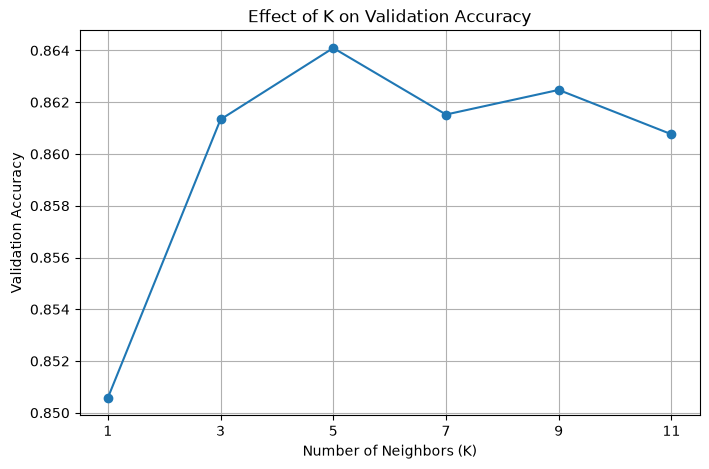

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    k_accuracies,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Validation Accuracy")
plt.title("Effect of K on Validation Accuracy")

plt.xticks(k_values)
plt.grid(True)
plt.show()

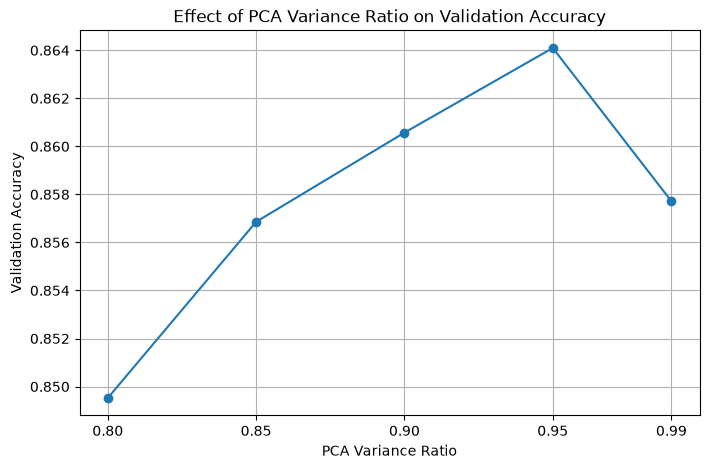

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    variance_ratios,
    pca_accuracies,
    marker="o"
)

plt.xlabel("PCA Variance Ratio")
plt.ylabel("Validation Accuracy")
plt.title("Effect of PCA Variance Ratio on Validation Accuracy")

plt.xticks(variance_ratios)
plt.grid(True)

plt.show()

In [19]:
best_config = {
    "PCA variance": 0.95,
    "PCA dimensions": 187,
    "K": 5,
    "Distance metric": "manhattan",
    "Weights": "distance",
    "Scaling": "minmax",
    "Validation Accuracy": 0.8689
}

for parameter, value in best_config.items():
    print(f"{parameter}: {value}")

PCA variance: 0.95
PCA dimensions: 187
K: 5
Distance metric: manhattan
Weights: distance
Scaling: minmax
Validation Accuracy: 0.8689
